In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import (
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    pipeline, DataCollatorForSeq2Seq, EarlyStoppingCallback
)
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from safetensors.torch import load_file

In [2]:
# Read the CSV file
data = pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/bible.csv")
extra_data=pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/Nagamese Khobor Comic and Other Resouces.csv")

In [3]:
print("Bible dataset:", len(data))
print("Non-Bible dataset:", len(extra_data))

Bible dataset: 7950
Non-Bible dataset: 821


In [4]:
# Load model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("facebook/nllb-200-distilled-600M")
model = AutoModelForSeq2SeqLM.from_pretrained("facebook/nllb-200-distilled-600M")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

In [5]:
data["source"] = "Bible"
extra_data["source"] = "Non-Bible"

data = data.dropna(subset=["English", "Nagamese"])
extra_data = extra_data.dropna(subset=["English", "Nagamese"])

data = data.drop_duplicates(subset=["English", "Nagamese"])
extra_data = extra_data.drop_duplicates(subset=["English", "Nagamese"])

train_df, val_df = train_test_split(
    data,
    test_size=0.10,
    random_state=61,
    shuffle=True
)

test_df = extra_data.copy()

train_source_texts = train_df["Nagamese"].tolist()
train_target_texts = train_df["English"].tolist()

val_source_texts = val_df["Nagamese"].tolist()
val_target_texts = val_df["English"].tolist()

test_source_texts = test_df["Nagamese"].tolist()
test_target_texts = test_df["English"].tolist()

print("Bible training samples:", len(train_df))
print("Bible validation samples:", len(val_df))
print("Non-Bible test samples:", len(test_df))

print("\nTraining source distribution:")
print(train_df["source"].value_counts())

print("\nValidation source distribution:")
print(val_df["source"].value_counts())

print("\nTest source distribution:")
print(test_df["source"].value_counts())


Bible training samples: 7154
Bible validation samples: 795
Non-Bible test samples: 819

Training source distribution:
source
Bible    7154
Name: count, dtype: int64

Validation source distribution:
source
Bible    795
Name: count, dtype: int64

Test source distribution:
source
Non-Bible    819
Name: count, dtype: int64


In [6]:
import random
random.seed(7)
# Combine and shuffle the training data
combined_train = list(zip(train_source_texts, train_target_texts))
random.shuffle(combined_train)

# Unzip back into separate lists
train_source_texts, train_target_texts = zip(*combined_train)
train_source_texts = list(train_source_texts)
train_target_texts = list(train_target_texts)

In [7]:
from datasets import Dataset

# Tokenize function
def tokenize_function(examples):
    model_inputs = tokenizer(examples["source_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")
    labels = tokenizer(examples["target_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")["input_ids"]
    # labels = [[-100 if token == tokenizer.pad_token_id else token for token in label] for label in labels]
    model_inputs["labels"]=labels
    return model_inputs

# Convert lists to Hugging Face Dataset
train_dataset = Dataset.from_dict({"source_texts": train_source_texts, "target_texts": train_target_texts})
val_dataset = Dataset.from_dict({"source_texts": val_source_texts, "target_texts": val_target_texts})

# Tokenize datasets
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])



Map:   0%|          | 0/7154 [00:00<?, ? examples/s]

Map:   0%|          | 0/795 [00:00<?, ? examples/s]

In [8]:
print(train_dataset["input_ids"][0])
print(train_dataset["input_ids"][1])

print(train_dataset["labels"][0])
print(train_dataset["labels"][1])

[4870, 541, 12361, 144194, 30532, 1700, 1275, 262, 777, 248079, 248059, 3, 167751, 28600, 228, 289, 8118, 115473, 172, 43833, 423, 181, 248079, 5244, 240, 337, 65529, 71499, 6888, 2137, 5244, 240, 18181, 854, 15, 30532, 330, 2768, 143, 27100, 83605, 248075, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[219599, 14763, 248079, 781, 16052, 780, 138897, 79369, 777, 3969, 30532, 28302, 172, 6888, 248079, 39271, 781, 103, 70676, 28302, 172, 6888, 248079, 3969, 30532, 780, 138897, 79706, 423, 298, 248075, 3, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

In [9]:
!pip install sacrebleu
import sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 5.9 MB/s eta 0:00:00


In [10]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)

    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)

    predictions = predictions.astype(np.int64)
    
    # ✅ Fix: clip to valid vocab range and replace negatives with pad token
    vocab_size = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size - 1)

    labels = np.where(
        labels == -100,
        tokenizer.pad_token_id,
        labels
    ).astype(np.int64)
    labels = np.clip(labels, 0, vocab_size - 1)  # ✅ also clip labels

    decoded_preds = tokenizer.batch_decode(predictions.tolist(), skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels.tolist(), skip_special_tokens=True)

    decoded_preds = [x.strip() for x in decoded_preds]
    decoded_labels = [x.strip() for x in decoded_labels]

    bleu = sacrebleu.corpus_bleu(decoded_preds, [decoded_labels])
    ter = sacrebleu.corpus_ter(decoded_preds, [decoded_labels])
    chrf = sacrebleu.corpus_chrf(decoded_preds, [decoded_labels])

    return {"bleu": bleu.score, "ter": ter.score, "chrf": chrf.score}

In [11]:
# Training Arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./results",
    logging_strategy="epoch", 
    eval_strategy="epoch", 
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_ratio=0.1,
    seed = 40,
    save_total_limit=2,
    num_train_epochs=10,
    predict_with_generate=True,
    optim="adafactor", 
    report_to=[],
    fp16=True,
    logging_dir="./logs",
    # overwrite_output_dir=True,
    load_best_model_at_end=True,
    disable_tqdm=True
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=1)],
    compute_metrics=compute_metrics,
)

# Start Training
trainer.train()


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


{'loss': '4.414', 'grad_norm': '1.628', 'learning_rate': '4.972e-05', 'epoch': '1'}
{'eval_loss': '0.4046', 'eval_bleu': '22.49', 'eval_ter': '71.67', 'eval_chrf': '40.55', 'eval_runtime': '91.06', 'eval_samples_per_second': '8.73', 'eval_steps_per_second': '0.549', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.3258', 'grad_norm': '2.658', 'learning_rate': '4.448e-05', 'epoch': '2'}
{'eval_loss': '0.2704', 'eval_bleu': '36.66', 'eval_ter': '56.37', 'eval_chrf': '53.62', 'eval_runtime': '96.45', 'eval_samples_per_second': '8.243', 'eval_steps_per_second': '0.518', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1479', 'grad_norm': '1.281', 'learning_rate': '2.781e-05', 'epoch': '5'}
{'eval_loss': '0.2553', 'eval_bleu': '41.05', 'eval_ter': '49.46', 'eval_chrf': '57.96', 'eval_runtime': '88.13', 'eval_samples_per_second': '9.021', 'eval_steps_per_second': '0.567', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '4437', 'train_samples_per_second': '16.12', 'train_steps_per_second': '2.017', 'train_loss': '1.059', 'epoch': '5'}


TrainOutput(global_step=4475, training_loss=1.0594711423053422, metrics={'train_runtime': 4437.1253, 'train_samples_per_second': 16.123, 'train_steps_per_second': 2.017, 'train_loss': 1.0594711423053422, 'epoch': 5.0})

In [12]:
model.save_pretrained("./nllb_model")
tokenizer.save_pretrained("./nllb_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./nllb_model/tokenizer_config.json', './nllb_model/tokenizer.json')

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "./nllb_model",
    attn_implementation="eager"
).to(device)
model.eval()

Using device: cuda


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


M2M100ForConditionalGeneration(
  (model): M2M100Model(
    (shared): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
    (encoder): M2M100Encoder(
      (embed_tokens): M2M100ScaledWordEmbedding(256206, 1024, padding_idx=1)
      (embed_positions): M2M100SinusoidalPositionalEmbedding()
      (layers): ModuleList(
        (0-11): 12 x M2M100EncoderLayer(
          (self_attn): M2M100Attention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): ReLU()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
       

In [14]:
source_texts = test_source_texts
reference_texts = test_target_texts

In [15]:
# Translate source texts using the model
model.eval()
machine_translations = []
batch_size=32
for i in range(0, len(source_texts), batch_size):
    batch_texts = source_texts[i : i + batch_size]  # Slice batch
    inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    with torch.no_grad():
        outputs = model.generate(**inputs)
    
    batch_translations = tokenizer.batch_decode(outputs, skip_special_tokens=True)
    machine_translations.extend(batch_translations)

In [16]:
wrapped_reference_texts = [reference_texts] 
bleu = sacrebleu.corpus_bleu(machine_translations, wrapped_reference_texts)
print("BLEU Score:", bleu.score)
ter = sacrebleu.corpus_ter(machine_translations, wrapped_reference_texts)
print("TER Score:", ter.score)
chrf = sacrebleu.corpus_chrf(machine_translations, wrapped_reference_texts)
print("CHRF Score:", chrf.score)

BLEU Score: 13.448554097136554
TER Score: 100.63424947145879
CHRF Score: 37.55387848487183


In [17]:
n = 31
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Jui mohina deh China para anti-espionage law introduce kurishae.
Translated: For seven months, China has introduced an anti-espionage law.
Reference: Last month, China introduced an anti-espionage law.


In [18]:
n = 81
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: kun phaale?
Translated: Who cares?
Reference: Which way?


In [19]:
n = 22
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Taila arrest tho Home minister Narayan Kaji Shrestha aro Finance Minister Prakash Sharan Mahat keh resign kuri kui nah demand kuri piche deh huishae.
Translated: Then the arrest was made by the Minister of the Interior Narayan Kaji Shrestha and the Minister of Finance Prakash Sharan Mahathir who resigned if they did not seek it after the demand.
Reference: The arrest comes days after he demanded the resignation of home minister Narayan Kaji Shrestha and finance minister Prakash Sharan Mahat.


Input:      Zeng kun ekta classified manu ase, education pursue kuribo karne tai keh Italy patai dishae aro tate taka time deh US embassy official ekjun lokot deh jinni jana manu hui shae kui shae CCTV report para.
Translated: He is a highly classified man, who was traveling to Italy to pursue his education when a delegation official from the U.S. Embassy came to the country to report on the CCTV.
Reference:  Zeng, who was regarded as a classified person, was sent to Italy to pursue further education and while there became acquainted with a US embassy official, said the CCTV report.


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

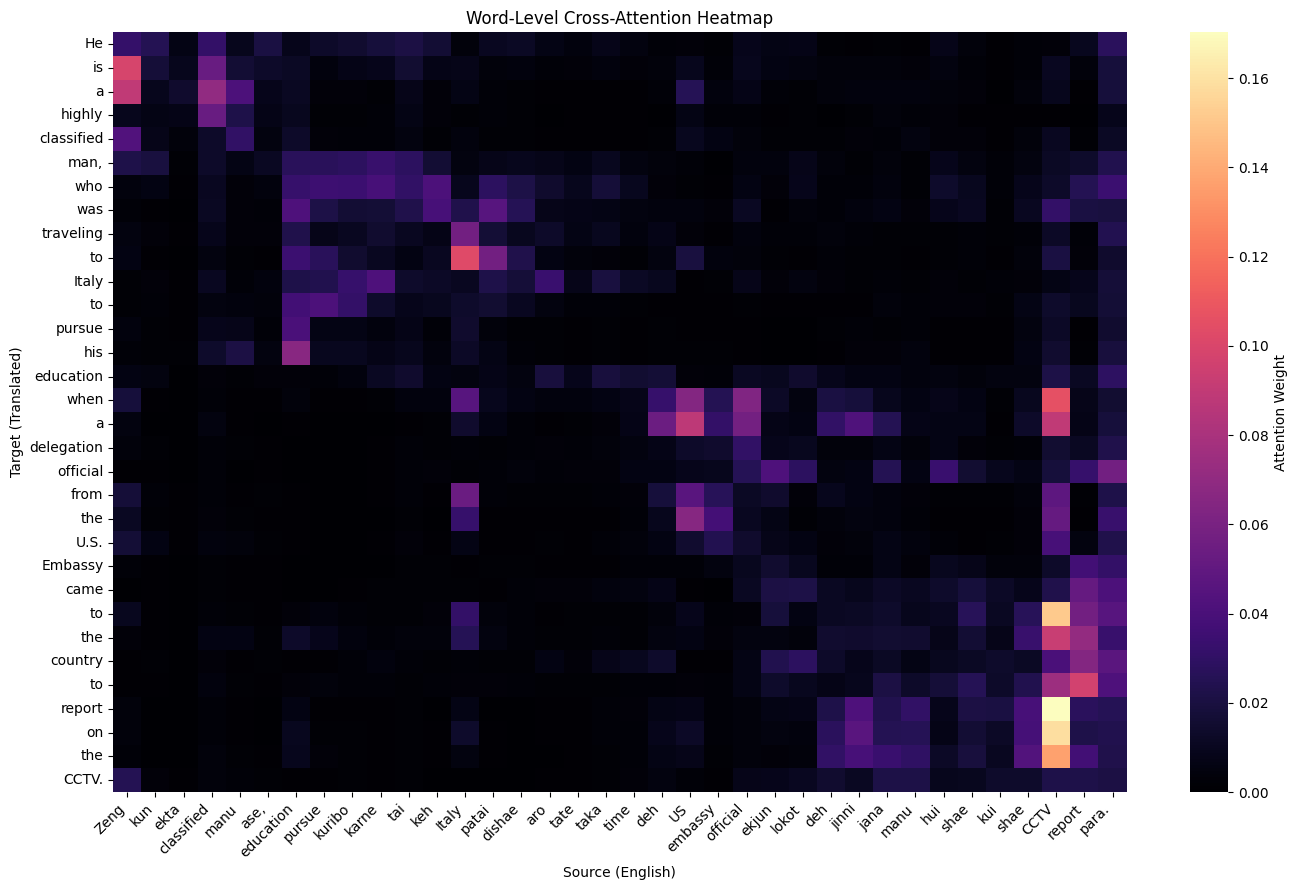


🔗 Word Alignments:

Target Word               →  Source Word
---------------------------------------------
He                        →  Zeng
is                        →  Zeng
a                         →  Zeng
highly                    →  classified
classified                →  Zeng
man,                      →  karne
who                       →  keh
was                       →  patai
traveling                 →  Italy
to                        →  Italy
Italy                     →  karne
to                        →  pursue
pursue                    →  education
his                       →  education
education                 →  para.
when                      →  CCTV
a                         →  CCTV
delegation                →  official
official                  →  para.
from                      →  Italy
the                       →  US
U.S.                      →  CCTV
Embassy                   →  report
came                      →  report
to                        →  CCTV
the        

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np

def merge_sentencepiece_tokens(tokens):
    words = []
    current_word = ""
    mapping = []
    word_idx = -1

    for i, tok in enumerate(tokens):
        if tok.startswith("▁") or tok.startswith("_"):  # SentencePiece or underscore-prefix
            if current_word:
                words.append(current_word)
            current_word = tok[1:]  # remove prefix
            word_idx += 1
        else:
            current_word += tok
        mapping.append(word_idx)
    if current_word:
        words.append(current_word)
    return words, mapping

def aggregate_attention(attn_matrix, src_map, tgt_map):
    num_tgt_words = max(tgt_map) + 1
    num_src_words = max(src_map) + 1
    agg_matrix = np.zeros((num_tgt_words, num_src_words))
    count_matrix = np.zeros((num_tgt_words, num_src_words))

    for i_tgt, tgt_word_idx in enumerate(tgt_map):
        for i_src, src_word_idx in enumerate(src_map):
            agg_matrix[tgt_word_idx][src_word_idx] += attn_matrix[i_tgt][i_src]
            count_matrix[tgt_word_idx][src_word_idx] += 1

    # Avoid division by zero
    count_matrix[count_matrix == 0] = 1
    return agg_matrix / count_matrix

# ----------------------------
# Your original pipeline
# ----------------------------
n = 28
tokenizer.src_lang = "eng_Latn"
tokenizer.tgt_lang = "eng_Latn"

inputs = tokenizer(
    source_texts[n], return_tensors="pt",
    max_length=128, truncation=True
).to(device)

with torch.no_grad():
    generated = model.generate(
        **inputs,
        max_length=128
    )

translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)
print(f"Input:      {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference:  {reference_texts[n]}")

decoder_input_ids = generated[:, :-1]

with torch.no_grad():
    out = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )

cross_attn_avg = out.cross_attentions[-1][0].mean(dim=0)  # [tgt_len, src_len]

# ── Token filtering ───────────────────────────────────────────────
special_ids = set(tokenizer.all_special_ids)

src_token_ids = inputs["input_ids"][0].tolist()
tgt_token_ids = decoder_input_ids[0].tolist()

# Build index maps: only keep non-special tokens, track their positions
src_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(src_token_ids) if tid not in special_ids]
tgt_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(tgt_token_ids) if tid not in special_ids]

src_indices, src_tokens_clean = zip(*src_keep) if src_keep else ([], [])
tgt_indices, tgt_tokens_clean = zip(*tgt_keep) if tgt_keep else ([], [])

src_indices = list(src_indices)
tgt_indices = list(tgt_indices)
src_tokens_clean = list(src_tokens_clean)
tgt_tokens_clean = list(tgt_tokens_clean)

# ── Slice attention to only non-special token positions ───────────
attn_np = cross_attn_avg.cpu().numpy()
attn_filtered = attn_np[np.ix_(tgt_indices, src_indices)]  # shape: [n_tgt_tokens, n_src_tokens]

# ── Merge subword tokens → words ──────────────────────────────────
src_words, src_map = merge_sentencepiece_tokens(src_tokens_clean)
tgt_words, tgt_map = merge_sentencepiece_tokens(tgt_tokens_clean)

word_attn = aggregate_attention(attn_filtered, src_map, tgt_map)

# ── Font fix for non-Latin scripts ────────────────────────────────
import matplotlib.font_manager as fm
# Use a font that supports Indic scripts if available, else fall back
try:
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSans/NotoSans-Regular.ttf",
        "/tmp/NotoSans-Regular.ttf"
    )
    prop = fm.FontProperties(fname="/tmp/NotoSans-Regular.ttf")
    font_name = prop.get_name()
    plt.rcParams["font.family"] = font_name
except Exception:
    pass  # silently skip if download fails

# ── Plot ──────────────────────────────────────────────────────────
plt.figure(figsize=(14, 9))
sns.heatmap(word_attn,
            xticklabels=src_words,
            yticklabels=tgt_words,
            cmap="magma",
            vmin=0, vmax=word_attn.max(),  # auto-scale vmax
            cbar_kws={"label": "Attention Weight"})
plt.title("Word-Level Cross-Attention Heatmap")
plt.xlabel("Source (English)")
plt.ylabel("Target (Translated)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Alignments ────────────────────────────────────────────────────
print("\n🔗 Word Alignments:\n")
print(f"{'Target Word':<25} →  Source Word")
print("-" * 45)
for tgt_idx, tgt_word in enumerate(tgt_words):
    if tgt_idx >= word_attn.shape[0]:
        break

    if word_attn.shape[1] == 0 or len(src_words) == 0:
        continue

    src_idx = int(np.argmax(word_attn[tgt_idx]))

    if src_idx < len(src_words):
        print(f"{tgt_word:<25} →  {src_words[src_idx]}")